**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

* **NOMBRE:** Federico Castro Zenteno
* **MATRÍCULA:** A01660986

Archivo de datos: `personal_loan.csv`. Coloca el CSV en la misma carpeta que esta libreta antes de ejecutar todo. En Colab, súbelo al directorio de trabajo desde el panel de archivos.

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [2]:
loan_df = pd.read_csv("personal_loan.csv", index_col="ID")
n_inicial = len(loan_df)
loan_df.info()
display(pd.Series({
    "Registros iniciales": n_inicial,
    "Columnas numéricas": len(loan_df.select_dtypes(include="number").columns),
    "Columnas de texto": len(loan_df.select_dtypes(exclude="number").columns)
}, name="Resumen inicial"))
display(loan_df.head())

<class 'pandas.DataFrame'>
RangeIndex: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   str    
 9   Securities Account  5037 non-null   str    
 10  CD Account          5037 non-null   str    
 11  Online              5037 non-null   str    
 12  CreditCard          5037 non-null   str    
dtypes: float64(2), int64(6), str(5)
memory usage: 511.7 KB


Registros iniciales    5037
Columnas numéricas        8
Columnas de texto         5
Name: Resumen inicial, dtype: int64

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


**Respuesta 1.** Hay **5,037 registros y 13 columnas** después de convertir `ID` en índice: **8 columnas numéricas** (6 enteras y 2 flotantes) y **5 columnas de texto**. Las cinco de texto corresponden a indicadores binarios con formatos mezclados. `ID` identifica al cliente, por lo que no se incluye en el análisis de atributos.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [3]:
display(loan_df.describe().T)
display(loan_df.isna().sum().rename("Faltantes"))
display(loan_df.loc[loan_df["Age"] > 100])

reglas_invalidas = pd.DataFrame({
    "Edad fuera de rango (0, 100]": (loan_df["Age"] <= 0) | (loan_df["Age"] > 100),
    "Experiencia negativa o mayor que edad": (loan_df["Experience"] < 0) | (loan_df["Experience"] > loan_df["Age"]),
    "Familia no positiva o no entera": (loan_df["Family"] < 1) | (loan_df["Family"] % 1 != 0),
    "Educación fuera de 1, 2, 3": ~loan_df["Education"].isin([1, 2, 3]),
    "Importes negativos": (loan_df[["Income", "CCAvg", "Mortgage"]] < 0).any(axis=1),
    "ZIP con formato irregular": ~loan_df["ZIP Code"].astype(str).str.fullmatch(r"[0-9]{5}")
}, index=loan_df.index)
display(reglas_invalidas.sum().rename("Registros por condición"))
invalido = reglas_invalidas.any(axis=1)
display(loan_df.loc[invalido])
n_invalidos = int(invalido.sum())
loan_df = loan_df.loc[~invalido].copy()
display(pd.Series({
    "Eliminados por valores inválidos": n_invalidos,
    "Porcentaje del total inicial": 100 * n_invalidos / n_inicial,
    "Registros restantes": len(loan_df)
}, name="Limpieza numérica"))

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
Name: Faltantes, dtype: int64

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


Edad fuera de rango (0, 100]              3
Experiencia negativa o mayor que edad    53
Familia no positiva o no entera           2
Educación fuera de 1, 2, 3                1
Importes negativos                        0
ZIP con formato irregular                 1
Name: Registros por condición, dtype: int64

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.40,3.0,0,0,0,0,No,0
15,60,30,22,95054,-1,1.50,3.0,0,0,No,0,Yes,Yes
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
250,144,6,29,94305,3,1.00,2.0,117,0,No,0,No,No
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
347,25,0,43,94305,2,1.60,7.3,0,0,Yes,Yes,1,Yes
384,51,25,21,9307,4,0.60,3.0,0,No,0,0,1,Yes
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No


Eliminados por valores inválidos      60.000000
Porcentaje del total inicial           1.191185
Registros restantes                 4977.000000
Name: Limpieza numérica, dtype: float64

**Respuesta 2.** Se aplican las siguientes decisiones:

- **Edad:** se eliminan 3 registros (ID 10, 250 y 4800), con edades de 123, 144 y 130 años. Se consideran errores de captura en este contexto bancario; no se intenta adivinar la edad correcta. No se supone que cualquier edad superior a 100 sea imposible universalmente.
- **Experiencia:** se eliminan 53 registros con años negativos; la duración de la experiencia laboral no puede ser negativa. No se reemplazan por cero porque eso equivaldría a inventar información. No hay experiencia mayor que la edad.
- **Familia:** se eliminan 2 registros con valores −1 y −3, imposibles para un conteo de personas. Los valores de 1 a 4 se conservan.
- **Educación:** se elimina 1 registro con 7.3; el diccionario sólo permite las categorías 1, 2 y 3.
- **Código postal:** se elimina 1 registro, ID 384, con `9307`, por formato irregular frente a los códigos de cinco dígitos del resto del archivo. Esta es una **suposición de calidad del dato**: el CSV no permite distinguir entre un dígito perdido y un cero inicial omitido. No se asigna un código corregido sin evidencia; si se obtiene el código original válido, este registro debería recuperarse.
- **Income, CCAvg y Mortgage:** no tienen valores negativos ni faltantes. Se conservan los importes altos porque son posibles y un valor atípico estadístico no constituye por sí solo un error. La hipoteca y el gasto en tarjeta pueden ser cero.

Las condiciones no se superponen en este archivo: se eliminan **60 registros, el 1.1912% de los 5,037 iniciales**, y quedan **4,977**. No hay datos faltantes. Este conteo corresponde a esta etapa; los duplicados se contabilizan en la pregunta 4.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [4]:
text_cols = loan_df.select_dtypes(exclude="number").columns.tolist()
display(loan_df[text_cols].describe().T)
for col in text_cols:
    display(loan_df[col].value_counts(dropna=False).rename_axis(col).to_frame("Frecuencia"))

bin_cols = ["Personal Loan", "Securities Account", "CD Account", "Online", "CreditCard"]
mapa_binario = {"0": 0, "1": 1, "no": 0, "yes": 1}
for col in bin_cols:
    normalizada = loan_df[col].astype(str).str.strip().str.lower().map(mapa_binario)
    if normalizada.isna().any():
        raise ValueError(f"Hay categorías binarias no reconocidas en {col}")
    loan_df[col] = normalizada.astype("int64")
display(loan_df[bin_cols].apply(pd.Series.value_counts).fillna(0).astype(int))

,count,unique,top,freq
Personal Loan,4977,4,0,3475
Securities Account,4977,4,No,2693
CD Account,4977,4,No,2462
Online,4977,4,Yes,1700
CreditCard,4977,4,0,2628


,Frecuencia
Personal Loan,
0,3475
No,1017
Yes,368
1,117


,Frecuencia
Securities Account,
No,2693
0,1765
Yes,390
1,129


,Frecuencia
CD Account,
No,2462
0,2212
1,163
Yes,140


,Frecuencia
Online,
Yes,1700
No,1628
1,1275
0,374


,Frecuencia
CreditCard,
0,2628
Yes,907
No,885
1,557


,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,4492,4458,4674,2002,3513
1,485,519,303,2975,1464


**Respuesta 3.** Las tablas muestran los descriptivos de las cinco variables de texto y la frecuencia de cada representación. En todas aparecen `0`, `1`, `No` y `Yes`. Se unifican **No/0 → 0** y **Yes/1 → 1**, donde 1 representa presencia del producto, uso del servicio o aceptación del préstamo, según el diccionario. Se comprueba que ninguna etiqueta quede sin mapear. Esta normalización permite detectar duplicados que antes tenían representaciones distintas.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [5]:
n_duplicados = int(loan_df.duplicated().sum())
display(loan_df.loc[loan_df.duplicated(keep=False)].sort_values(list(loan_df.columns)))
loan_df = loan_df.drop_duplicates().reset_index(drop=True)
display(pd.Series({
    "Duplicados eliminados": n_duplicados,
    "Total eliminado (inválidos + duplicados)": n_inicial - len(loan_df),
    "Porcentaje total eliminado": 100 * (n_inicial - len(loan_df)) / n_inicial,
    "Registros finales": len(loan_df),
    "Primer índice": loan_df.index.min(),
    "Último índice": loan_df.index.max()
}, name="Resultado de limpieza"))

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
1160,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
5031,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
3673,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
5032,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
2101,35,5,203,95032,1,10.0,3.0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5026,64,37,138,94709,2,2.8,2.0,0,1,0,0,1,0
767,64,39,38,92024,1,1.1,3.0,108,0,0,0,0,0
5016,64,39,38,92024,1,1.1,3.0,108,0,0,0,0,0


Duplicados eliminados                         36.000000
Total eliminado (inválidos + duplicados)      96.000000
Porcentaje total eliminado                     1.905896
Registros finales                           4941.000000
Primer índice                                  0.000000
Último índice                               4940.000000
Name: Resultado de limpieza, dtype: float64

**Respuesta 4.** Después de normalizar los indicadores se encuentran **36 registros duplicados adicionales**; se conserva la primera ocurrencia de cada combinación de atributos. `duplicated()` compara todas las columnas de atributos y excluye el índice `ID`, que es distinto para cada fila. Esta es la definición de duplicado usada en la actividad; en datos reales, atributos iguales no garantizan que se trate de la misma persona.

El índice se reinicia de **0 a 4,940**. Quedan **4,941 registros**. La limpieza completa elimina **96 registros**, equivalentes al **1.9059%** del total inicial.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [6]:
loan_df["ZIP Code"] = loan_df["ZIP Code"].astype(str).astype("object")
loan_df["Education"] = loan_df["Education"].astype(int).astype(
    pd.CategoricalDtype(categories=[1, 2, 3], ordered=True)
)
for col in bin_cols:
    loan_df[col] = loan_df[col].astype(pd.CategoricalDtype(categories=[0, 1]))

num_cols = loan_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()
display(loan_df.dtypes.rename("Tipo final").to_frame())
display(pd.Series({"num_cols": num_cols, "cat_cols": cat_cols}, name="Listas de variables"))

,Tipo final
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


num_cols    [Age, Experience, Income, Family, CCAvg, Mortg...
cat_cols    [ZIP Code, Education, Personal Loan, Securitie...
Name: Listas de variables, dtype: object

**Respuesta 5.** `num_cols` contiene **Age, Experience, Income, Family, CCAvg y Mortgage**; `cat_cols` contiene **ZIP Code, Education, Personal Loan, Securities Account, CD Account, Online y CreditCard**.

`Age` y `Experience` son duraciones registradas en años enteros; `Family` es un conteo discreto. `Income`, `CCAvg` y `Mortgage` son magnitudes monetarias de naturaleza continua aunque algunas se almacenen como enteros. `ZIP Code` es nominal, sin significado aritmético. `Education` es ordinal con el orden 1 < 2 < 3 solicitado. Los cinco indicadores son categóricos binarios. `Family` permanece numérica para seguir las conversiones requeridas, pero sus gráficos se interpretan como un conteo.

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [7]:
estadisticas = loan_df[num_cols].describe().T
estadisticas["Asimetría"] = loan_df[num_cols].skew()
estadisticas["Curtosis (exceso)"] = loan_df[num_cols].kurt()
display(estadisticas)

,count,mean,std,min,25%,50%,75%,max,Asimetría,Curtosis (exceso)
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


**Respuesta 6.** Se utiliza la **curtosis de exceso de Fisher** que calcula pandas: la distribución normal tiene valor 0. Como guía descriptiva, |asimetría| < 0.5 indica simetría aproximada, entre 0.5 y 1 asimetría moderada y > 1 asimetría alta; no es una prueba de normalidad.

| Variable | Asimetría | Exceso de curtosis | Clasificación |
|---|---:|---:|---|
| Age | −0.0228 | −1.1616 | Aproximadamente simétrica, platicúrtica |
| Income | 0.8420 | −0.0462 | Asimetría positiva moderada, aproximadamente mesocúrtica |
| Mortgage | 2.1039 | 4.7600 | Asimetría positiva alta, leptocúrtica |

La curtosis de Income es cercana a cero, pero eso no implica normalidad: la asimetría y la forma completa también deben evaluarse. Mortgage combina numerosos ceros con importes positivos altos.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

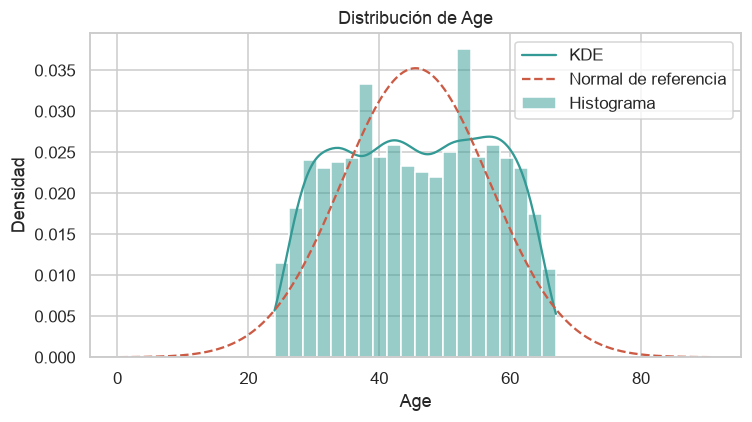

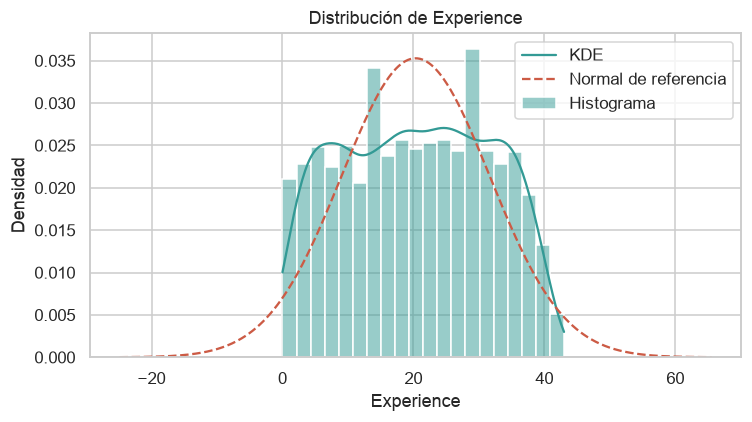

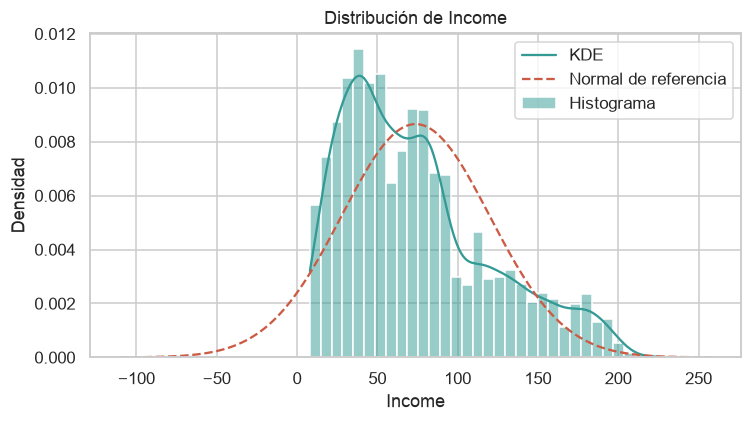

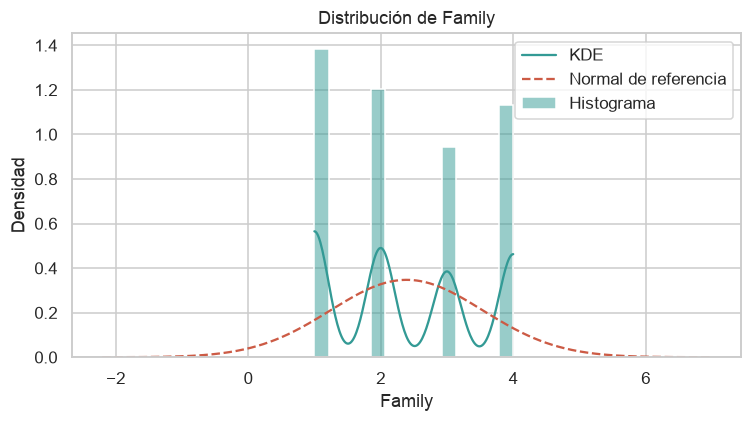

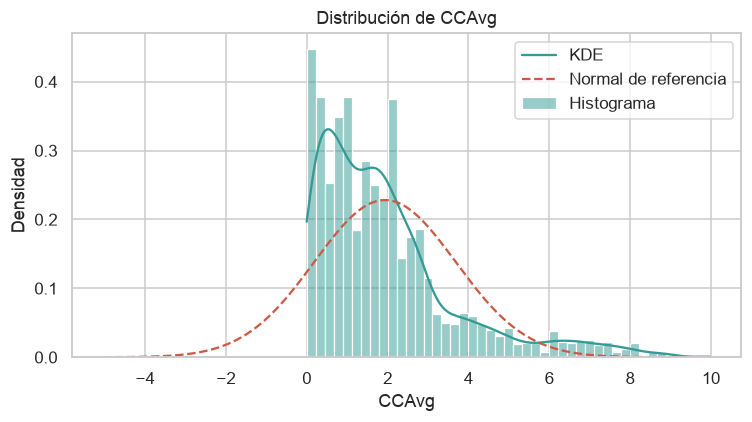

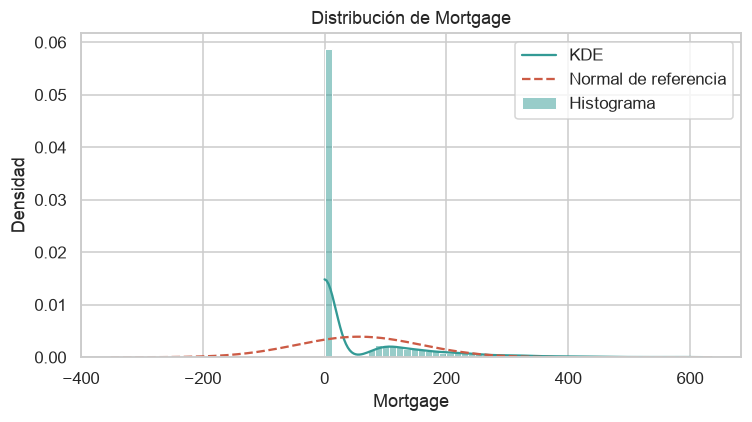

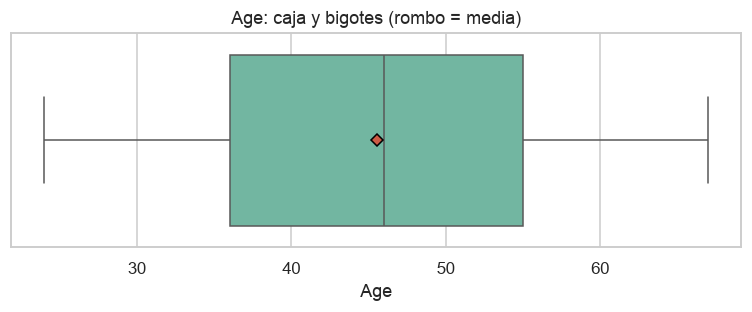

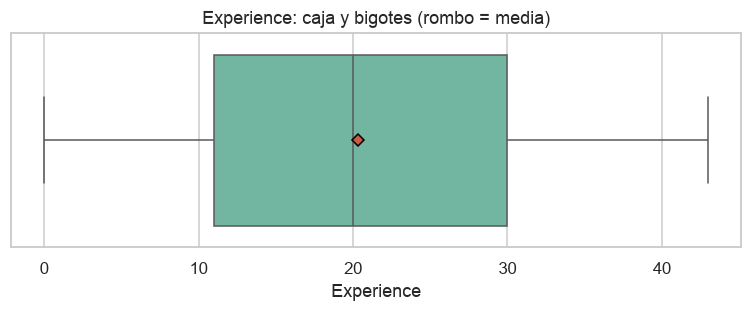

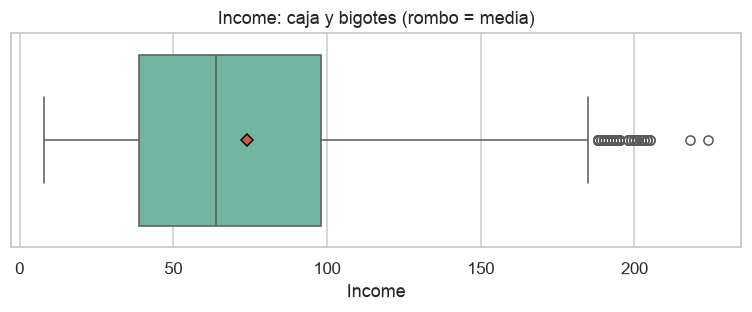

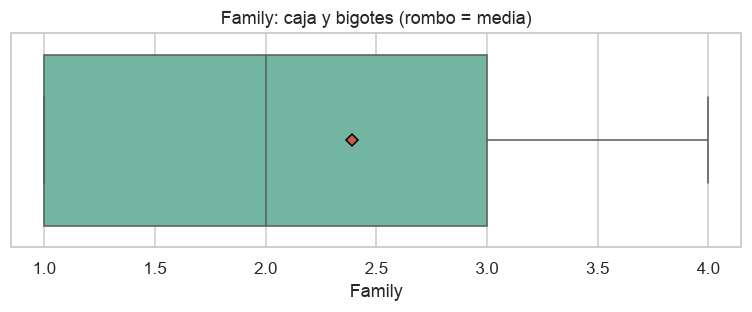

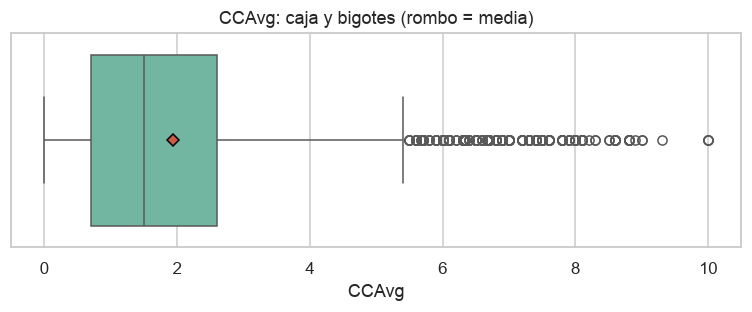

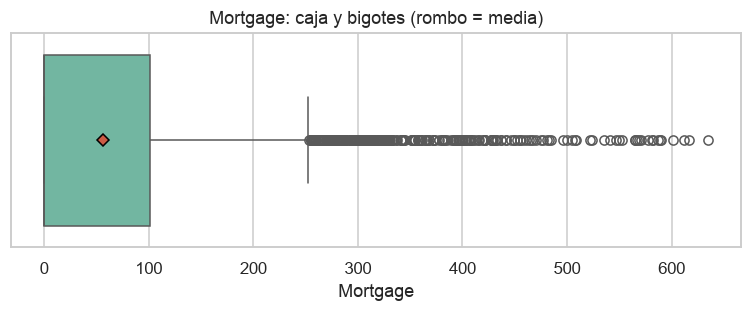

,Media,Mediana,Media − mediana,Asimetría
Age,45.560210,46.0,-0.439790,-0.022754
Experience,20.335357,20.0,0.335357,-0.015216
Income,73.826553,64.0,9.826553,0.841991
Family,2.391621,2.0,0.391621,0.159463
CCAvg,1.935855,1.5,0.435855,1.594670
Mortgage,56.663631,0.0,56.663631,2.103865


In [8]:
for col in num_cols:
    valores = loan_df[col]
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(valores, stat="density", kde=True, bins="auto", ax=ax, color="#339a95", label="Histograma")
    ax.lines[0].set_label("KDE")
    mu, sigma = valores.mean(), valores.std()
    x = np.linspace(min(valores.min(), mu - 4*sigma), max(valores.max(), mu + 4*sigma), 500)
    ax.plot(x, norm.pdf(x, loc=mu, scale=sigma), color="#cc5b45", linestyle="--", label="Normal de referencia")
    ax.set(title=f"Distribución de {col}", xlabel=col, ylabel="Densidad")
    ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)

for col in num_cols:
    fig, ax = plt.subplots(figsize=(7, 3))
    sns.boxplot(x=loan_df[col], showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "#cc5b45", "markeredgecolor": "black"}, ax=ax)
    ax.set_title(f"{col}: caja y bigotes (rombo = media)")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

display(pd.DataFrame({
    "Media": loan_df[num_cols].mean(),
    "Mediana": loan_df[num_cols].median(),
    "Media − mediana": loan_df[num_cols].mean() - loan_df[num_cols].median(),
    "Asimetría": loan_df[num_cols].skew()
}))

**Respuesta 7.** Los histogramas coinciden con los momentos calculados: **Age** es relativamente uniforme en el rango observado y casi simétrica, con una forma más plana que la normal; **Income** presenta una cola derecha y su KDE no reproduce una campana simétrica; **Mortgage** concentra muchas observaciones en cero y muestra una cola larga a la derecha, consistente con su asimetría alta y exceso de curtosis positivo.

La normal de referencia se ajusta con la media y desviación estándar de cada variable, sin afirmar que los datos sean normales. En variables no negativas, la curva normal puede extenderse a valores negativos; esto evidencia una limitación del modelo de referencia. La KDE es una aproximación suavizada: en `Family`, una variable discreta, no implica que existan tamaños de familia fraccionarios.

| Variable | Media | Mediana | Interpretación |
|---|---:|---:|---|
| Age | 45.56 | 46 | Diferencia pequeña; simetría aproximada con sesgo negativo mínimo |
| Experience | 20.34 | 20 | Diferencia pequeña; casi simétrica (asimetría −0.0152) |
| Income | 73.83 | 64 | Los ingresos altos elevan la media; sesgo positivo |
| Family | 2.39 | 2 | Media mayor en un conteo discreto; sesgo positivo leve (0.1595) |
| CCAvg | 1.94 | 1.50 | Gastos altos elevan la media; sesgo positivo marcado |
| Mortgage | 56.66 | 0 | Muchos clientes sin hipoteca y pocos importes altos; sesgo positivo marcado |

La relación media–mediana es una guía, no una equivalencia exacta con el signo del tercer momento. `Experience` ilustra esto: la media es ligeramente mayor que la mediana, pero la asimetría es prácticamente cero y ligeramente negativa. Los puntos fuera de los bigotes se conservan cuando son plausibles.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

,count,unique,top,freq
ZIP Code,4941,467,94720,163
Education,4941,3,1,2079
Personal Loan,4941,2,0,4462
Securities Account,4941,2,0,4426
CD Account,4941,2,0,4640
Online,4941,2,1,2951
CreditCard,4941,2,0,3489


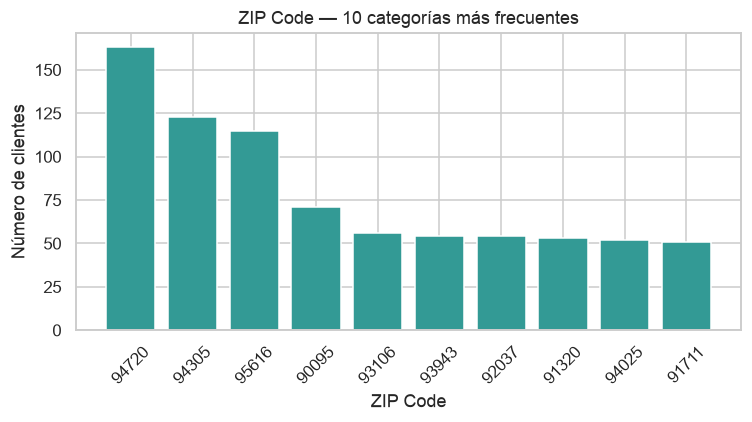

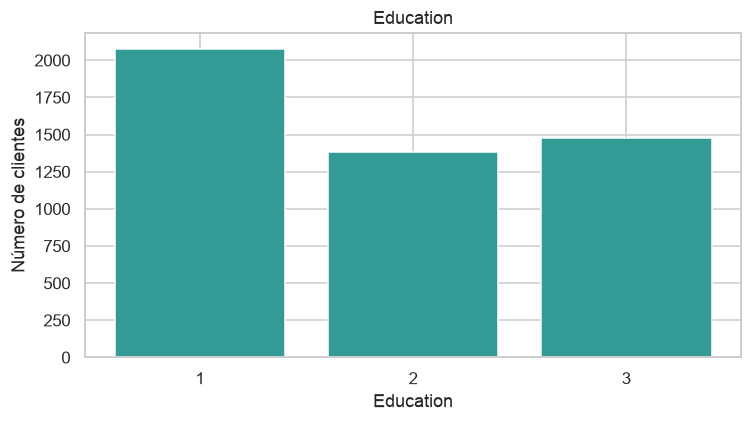

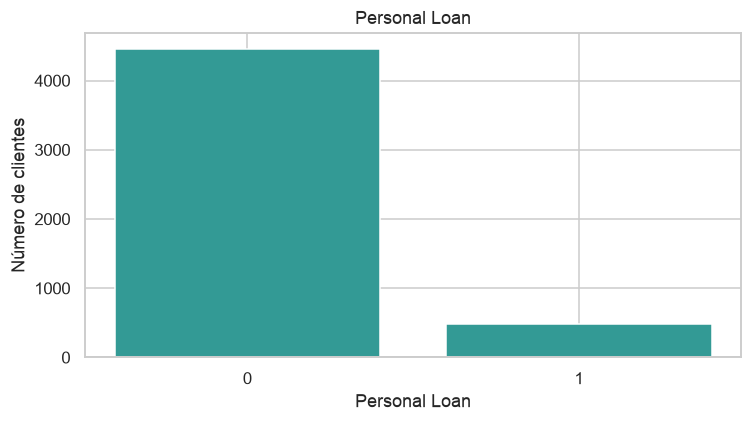

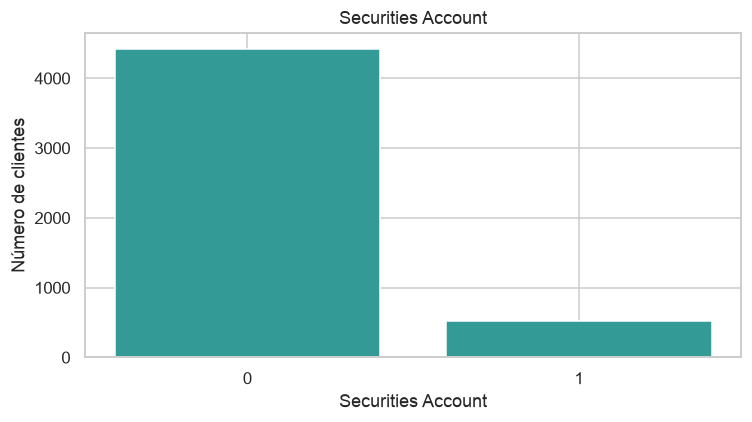

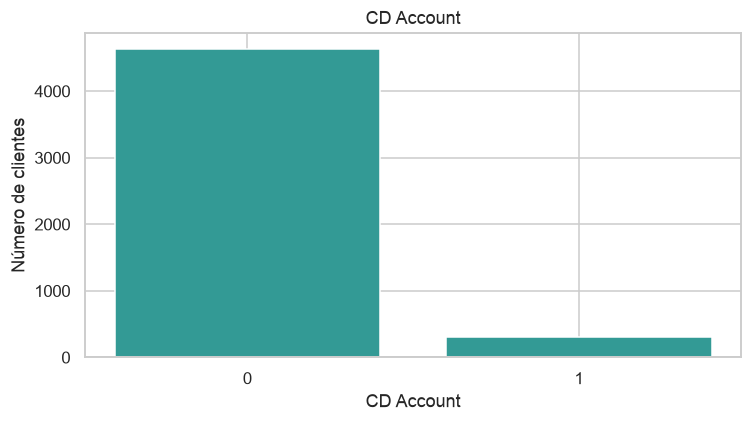

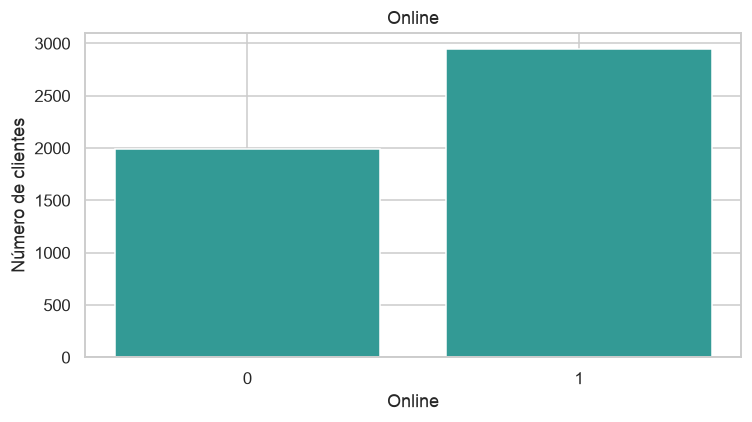

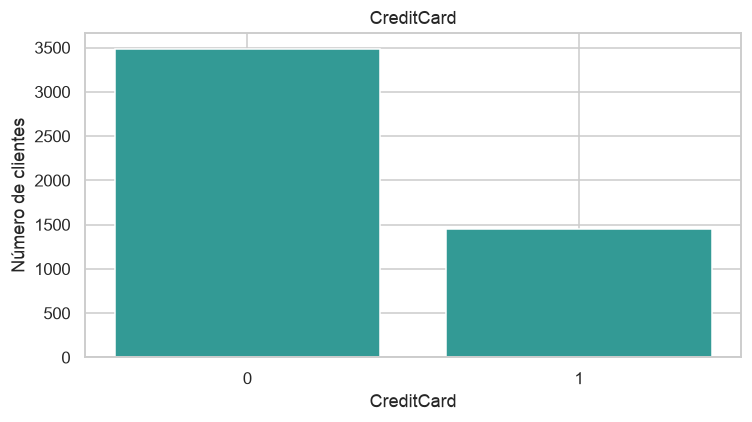

In [9]:
display(loan_df[cat_cols].describe().T)
for col in cat_cols:
    frecuencias = loan_df[col].value_counts().sort_values(ascending=False)
    alta_cardinalidad = len(frecuencias) > 10
    if alta_cardinalidad:
        frecuencias = frecuencias.head(10)
    else:
        frecuencias = frecuencias.sort_index()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(frecuencias.index.astype(str), frecuencias.values, color="#339a95")
    ax.set(title=f"{col}" + (" — 10 categorías más frecuentes" if alta_cardinalidad else ""),
           xlabel=col, ylabel="Número de clientes")
    ax.tick_params(axis="x", rotation=45 if alta_cardinalidad else 0)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

**Respuesta 8.** Cada gráfico representa frecuencias absolutas. Para `ZIP Code`, de alta cardinalidad, se presentan únicamente los **10 códigos más frecuentes**, como criterio de relevancia; no representan toda su distribución. En Educación y las binarias se muestran todas las categorías. En `Personal Loan` predomina 0, por lo que las clases de la variable de salida están desbalanceadas; las comparaciones posteriores deben considerar proporciones dentro de cada grupo.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

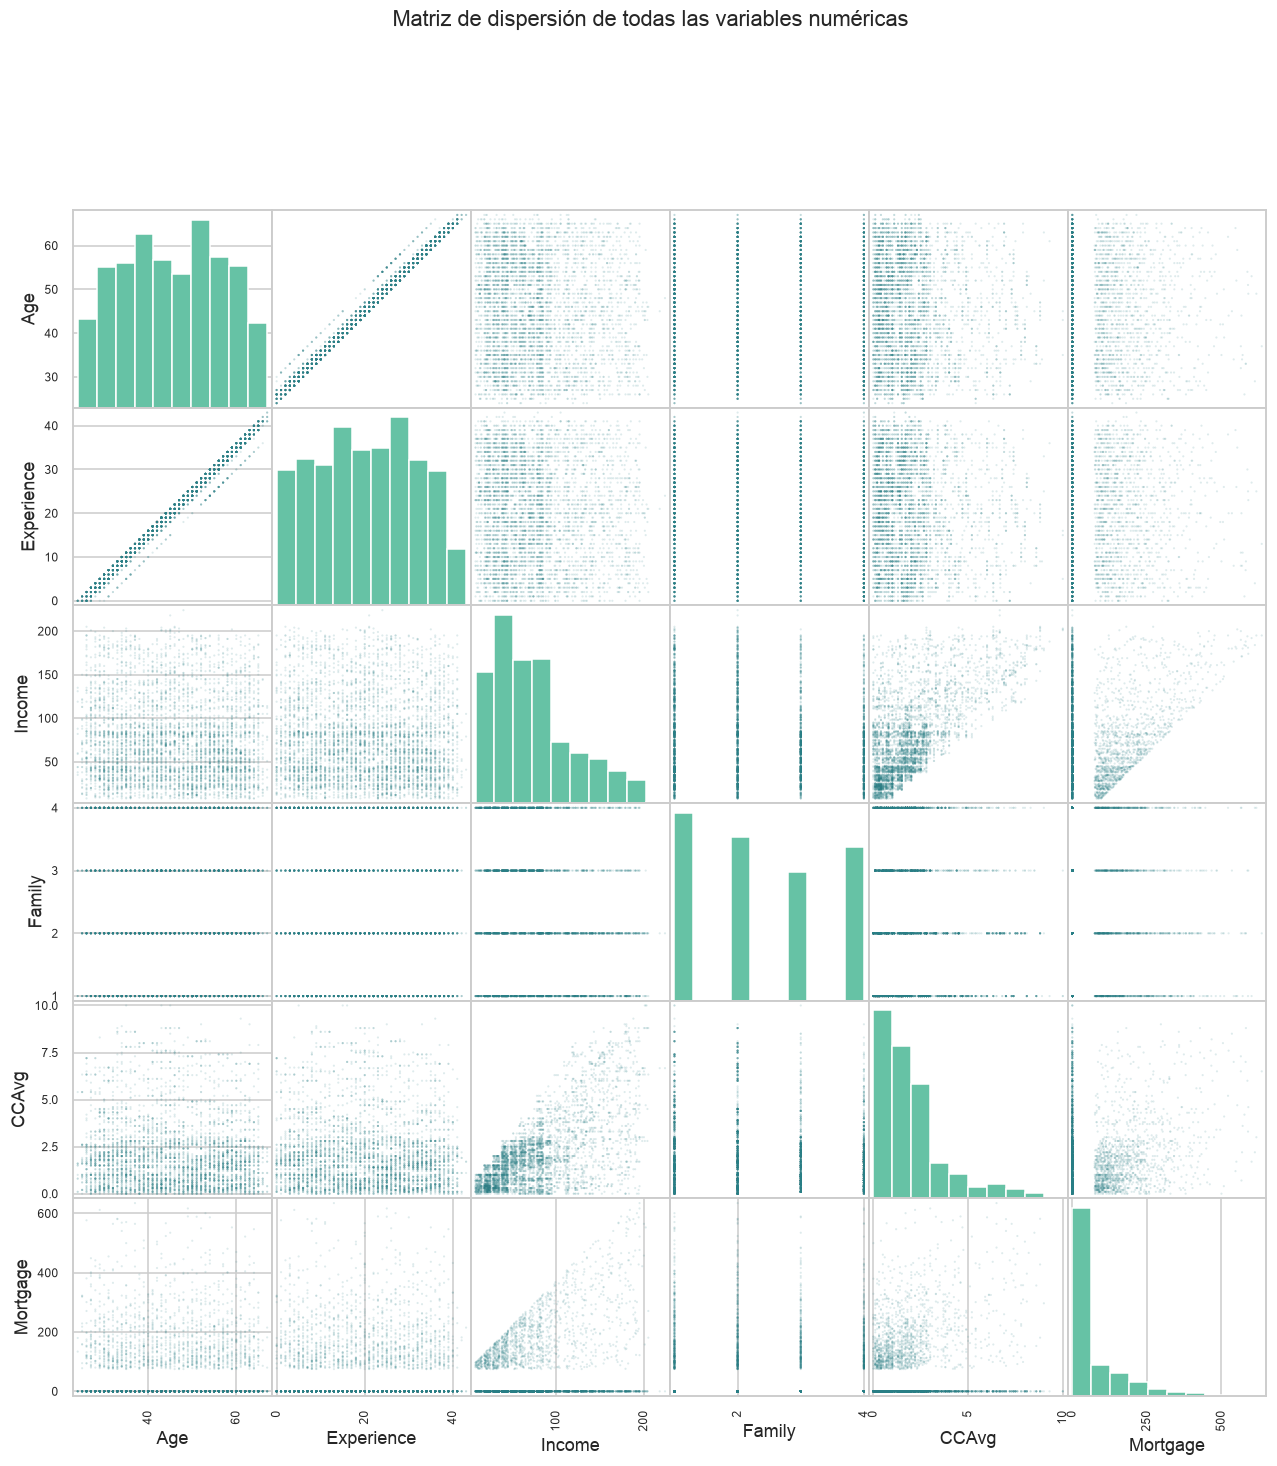

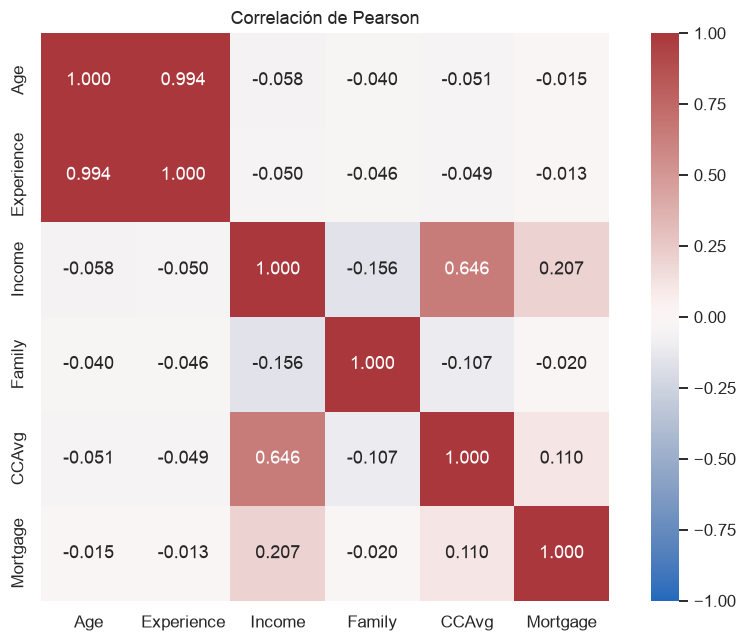

In [10]:
axes = pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(14, 14),
                                  diagonal="hist", alpha=0.15, s=8, color="#287e85")
fig = axes[0, 0].figure
fig.suptitle("Matriz de dispersión de todas las variables numéricas", y=1.01)
plt.show()
plt.close(fig)

correlacion = loan_df[num_cols].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1,
            center=0, square=True, ax=ax)
ax.set_title("Correlación de Pearson")
fig.tight_layout()
plt.show()
plt.close(fig)

**Respuesta 9.** El par **Age–Experience** muestra una nube muy estrecha alrededor de una recta ascendente: a mayor edad, generalmente mayor experiencia. La correlación de Pearson es **r = 0.994**, positiva y muy fuerte, consistente con lo observado en la matriz. Las franjas se deben al registro en años enteros. Las variables comparten información y podrían producir redundancia al construir un modelo.

También se observa una relación positiva entre **Income y CCAvg (r = 0.646)**: el gasto con tarjeta tiende a aumentar con el ingreso, aunque hay dispersión. Las demás correlaciones lineales son bastante menores. Una correlación baja no descarta relaciones no lineales, y ninguna de estas asociaciones demuestra causalidad.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.

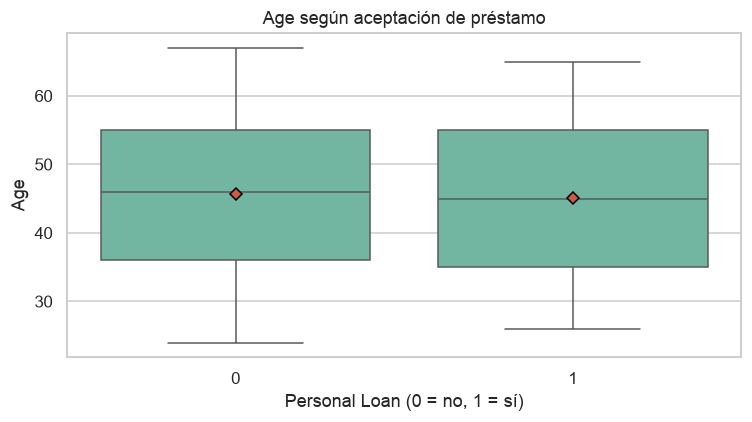

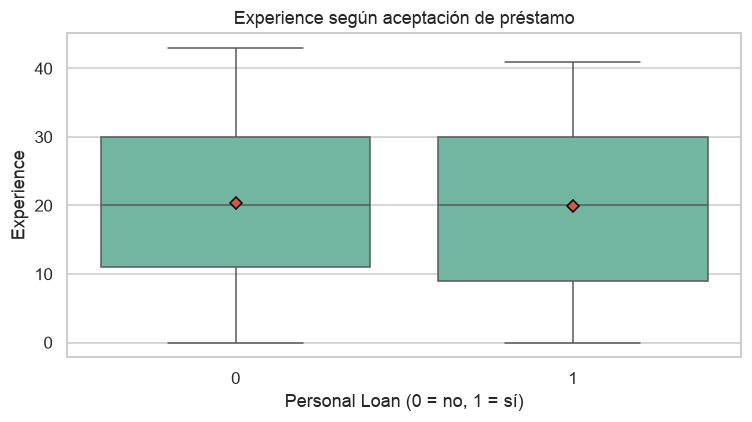

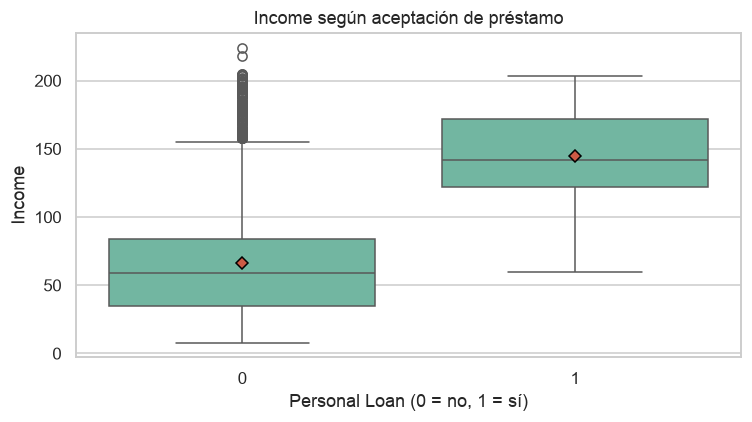

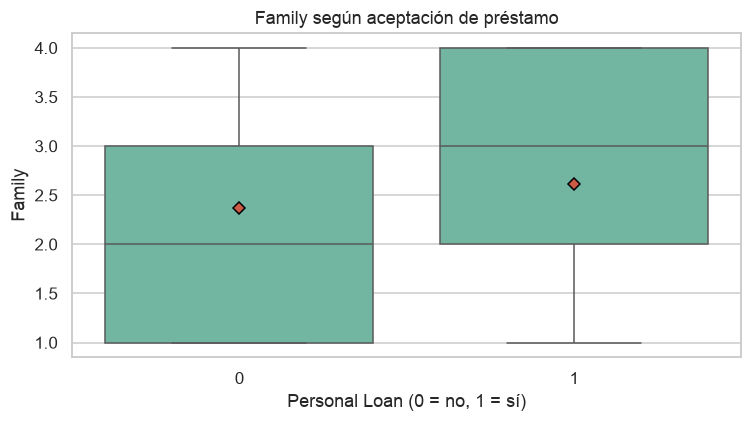

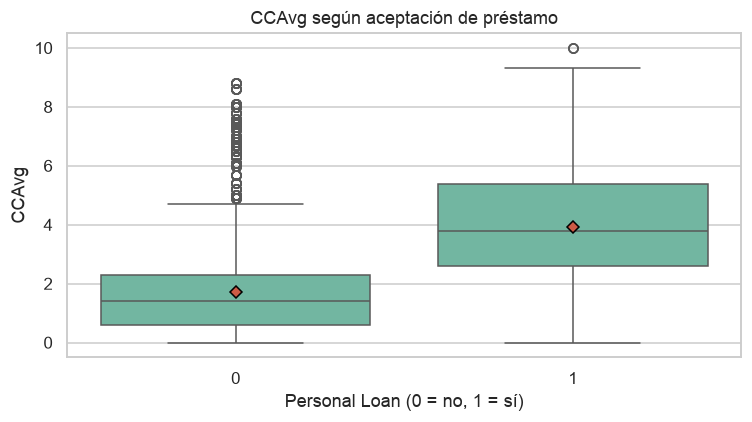

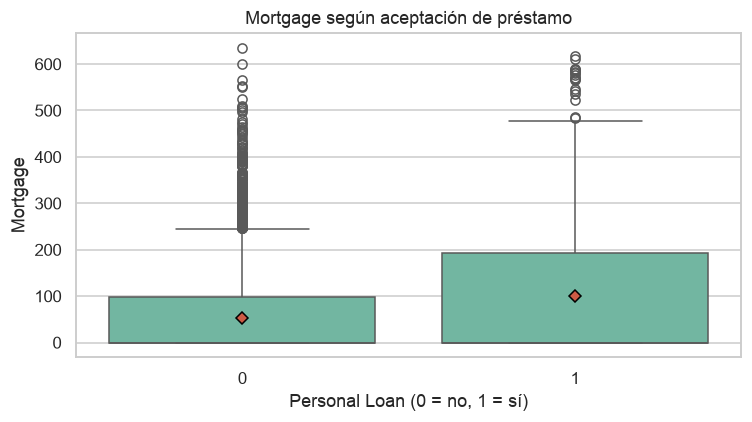

Personal Loan,0,1
Age,46.0,45.0
Experience,20.0,20.0
Income,59.0,142.0
Family,2.0,3.0
CCAvg,1.4,3.8
Mortgage,0.0,0.0


Personal Loan
0    4462
1     479
Name: Clientes por clase, dtype: int64

,Clientes,Aceptación (%)
Education,,
1,2079,4.473304
2,1385,13.068592
3,1477,13.879485


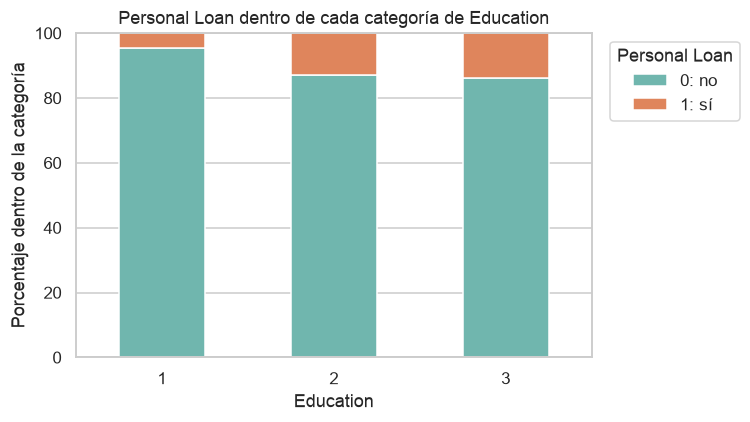

,Clientes,Aceptación (%)
Securities Account,,
0,4426,9.466787
1,515,11.650485


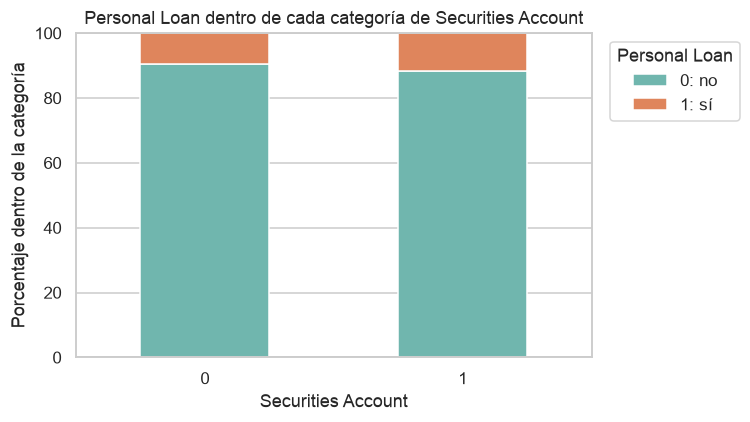

,Clientes,Aceptación (%)
CD Account,,
0,4640,7.306034
1,301,46.511628


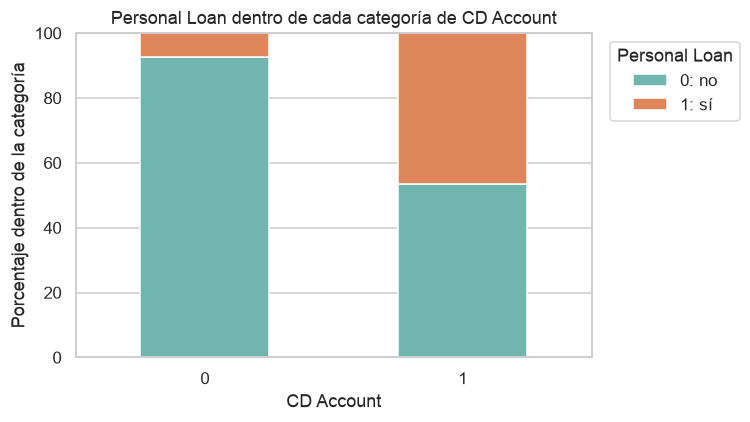

,Clientes,Aceptación (%)
Online,,
0,1990,9.447236
1,2951,9.861064


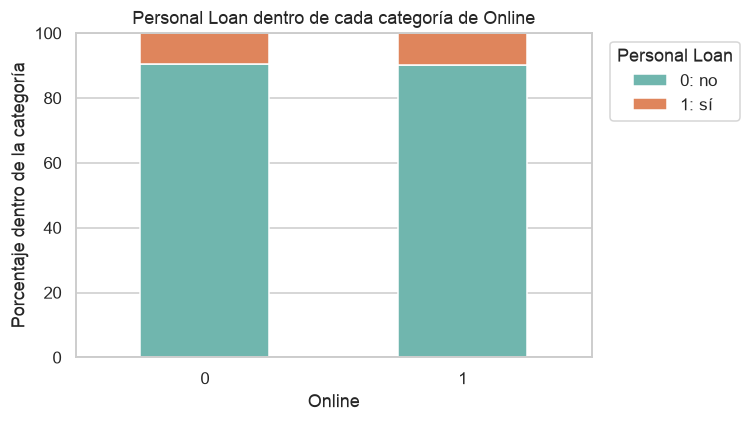

,Clientes,Aceptación (%)
CreditCard,,
0,3489,9.630267
1,1452,9.848485


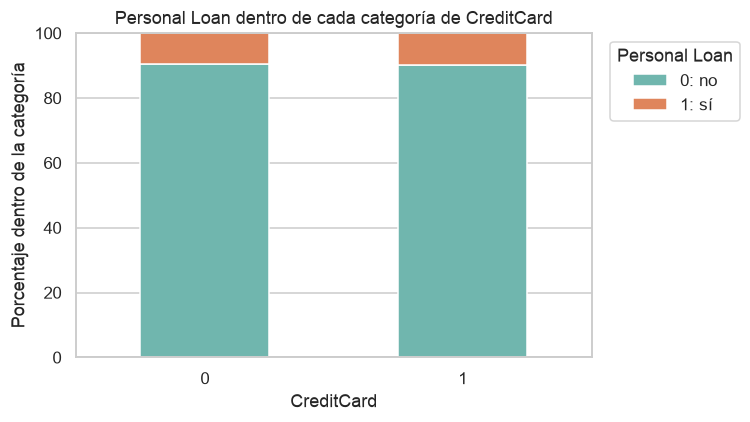

In [11]:
for col in num_cols:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=loan_df, x="Personal Loan", y=col, order=[0, 1], showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "#cc5b45", "markeredgecolor": "black"}, ax=ax)
    ax.set(title=f"{col} según aceptación de préstamo", xlabel="Personal Loan (0 = no, 1 = sí)")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

display(loan_df.groupby("Personal Loan", observed=True)[num_cols].median().T)
display(loan_df["Personal Loan"].value_counts().sort_index().rename("Clientes por clase"))

cat_predictoras = [col for col in cat_cols if col not in ["ZIP Code", "Personal Loan"]]
for col in cat_predictoras:
    conteos = pd.crosstab(loan_df[col], loan_df["Personal Loan"], dropna=False)
    proporciones = conteos.div(conteos.sum(axis=1), axis=0) * 100
    display(pd.DataFrame({"Clientes": conteos.sum(axis=1), "Aceptación (%)": proporciones[1]}))
    ax = proporciones.plot(kind="bar", stacked=True, figsize=(7, 4), color=["#70b6ae", "#df855c"])
    ax.set(title=f"Personal Loan dentro de cada categoría de {col}", xlabel=col, ylabel="Porcentaje dentro de la categoría", ylim=(0, 100))
    ax.legend(title="Personal Loan", labels=["0: no", "1: sí"], bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.tick_params(axis="x", rotation=0)
    fig = ax.figure
    fig.tight_layout()
    plt.show()
    plt.close(fig)

**Respuesta 10.**

**Variables numéricas.** Entre quienes aceptaron el préstamo, la mediana del ingreso anual es **142 mil USD**, frente a **59 mil USD** entre quienes no lo aceptaron. La mediana del gasto mensual con tarjeta es **3.8 mil USD** frente a **1.4 mil USD**. Estos grupos presentan una separación apreciable en los boxplots, aunque sus distribuciones se superponen. La mediana de `Family` pasa de 2 a 3; edad (46 frente a 45) y experiencia (20 en ambos grupos) muestran diferencias menores. La mediana de `Mortgage` es cero en ambas clases: esa medida por sí sola no resume las diferencias de las colas.

**Variables categóricas.** La aceptación entre clientes con **CD Account = 1** es **46.51%**, frente a **7.31%** con CD Account = 0. Para `Education`, las tasas son **4.47%**, **13.07%** y **13.88%** en los niveles 1, 2 y 3. `Securities Account` muestra una diferencia menor (11.65% con cuenta y 9.47% sin ella); `Online` y `CreditCard` tienen tasas próximas entre sus categorías. Las tablas incluyen el tamaño de cada grupo para contextualizar los porcentajes.

Cada barra suma 100% **dentro de la categoría de la variable explicativa**, evitando confundir el tamaño del grupo con su proporción de aceptación. Se excluyen `ZIP Code`, según la instrucción, y `Personal Loan` como predictor de sí mismo, porque esa comparación sería trivial. La distribución global de `Personal Loan` ya se muestra en la pregunta 8 y en el conteo de esta sección.

Las asociaciones descritas son exploratorias, no evidencia causal ni garantías de predicción. Se refieren al dataset limpio y dependen de las decisiones de exclusión documentadas.

---
**Declaración de uso de IA**

OpenAI. (2026). *Codex (basado en GPT-6)* [Modelo de lenguaje grande], utilizado para generar código de limpieza y análisis exploratorio, redactar interpretaciones de resultados y apoyar la depuración y verificación de la ejecución secuencial de esta libreta. https://openai.com/codex/

La actividad fue elaborada con asistencia de IA. El estudiante deberá revisar el código, las decisiones de limpieza y las conclusiones y asumir la responsabilidad del contenido que entregue.